# Step 5 (gimbal phase 2): Motor torque, open loop

## 1. Where we start, what we want, what we get

| | |
|---|---|
| **We have** | the full passive model from phase 1, plus two torque motors (one per hinge): gear 1, command limit $\pm3$ N·m |
| **Unknown** | the motion under a torque that we choose in advance (no feedback) |
| **Set to 0 (still)** | noise $=0$. Friction is run both off and on (two runs) |
| **NEW in this step** | the motor torque $\mathbf u$ in $\boldsymbol\tau$: command, clip, gear |
| **What we get** | trajectories under constant commands, including one that saturates |
| **Pass rule** | frictionless runs: $10^{-6}$ rad; run with damping and friction: $10^{-3}$ rad |

## 2. The equations

**5.1 Motor torque.** The command $\mathbf c_{\text{cmd}}$ is a number we choose for each motor. The motor clips it to its limit, and the gear multiplies it:

$$u_i=G\cdot\operatorname{clip}\!\left(c_{\text{cmd},i},\,-\tau_{\max},\,+\tau_{\max}\right)$$

**5.2 The torque is a generalized force on its own hinge.** The motor pushes about the hinge axis, so its virtual work is $u_i\,\delta q_i$ and it enters the right-hand side of the equation of motion as $u_i$ in row $i$. There is no cross-coupling because the inner hinge axis is perpendicular to the outer one.

**5.3 Equation of motion with the motor**

$$M(q)\,\ddot q+\mathbf h+\mathbf g=\mathbf u-b\,\dot q-c\tanh\!\left(\frac{\dot q}{\varepsilon}\right)\ \Rightarrow\ \ddot q_i=\frac{u_i-b\dot q_i-c\tanh(\dot q_i/\varepsilon)-h_i-g_i}{M_{ii}}$$

**5.4 The torque is held constant over one step.** MuJoCo sets the command once per step. So in RK4 the same $\mathbf u$ is used in all four stages $k_1$ to $k_4$ (equations 1.9 unchanged).

**5.5 First acceleration (hand check).** At rest, $\mathbf h=0$ and friction is zero, so

$$\ddot q_i(0)=\frac{u_i-g_i(q_0)}{M_{ii}(q_0)}$$

| Symbol | Meaning | Unit | Status | Code name |
|---|---|---|---|---|
| $c_{\text{cmd},i}$ | motor command | N·m | **NEW**, known input (we choose) | `motor_command` |
| $G$ | gear ratio | 1 | **NEW**, known input (1) | `motor_gear` |
| $\tau_{\max}$ | command limit | N·m | **NEW**, known input (3) | `motor_torque_limit` |
| $u_i$ | motor torque on hinge $i$ | N·m | **NEW**, output | `motor_torque` |

**Cases run in the notebook**

| Case | Command (N·m) | Friction | Tolerance |
|---|---|---|---|
| a | $(+0.5,\ -0.5)$, for 1.0 s | off | $10^{-6}$ rad |
| b | $(+5,\ -5)$, clipped to $(+3,\ -3)$, for 0.5 s | off | $10^{-6}$ rad |
| c | $(+0.5,\ -0.5)$, for 1.0 s | $b=0.04$, $c=0.02$ | $10^{-3}$ rad |

## 3. Plug in, get out

```
command (we choose) -> 5.1 clip and gear -> u
   -> 5.3 q_ddot (with u constant over the step) -> RK4 -> next state
   -> compare with MuJoCo (same constant ctrl, same friction settings)
```

## 4. Conclusion

You hold a simulator that responds to torque and saturates like the real motors. The saturation case is the check that the clip is right: the logged torque must read $\pm3$ N·m when the command is $\pm5$.


## Code

Names in the code follow the `Code name` columns of the tables above.

In [1]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

from mujoco_reference import run_mujoco, mujoco_mass_and_bias  # reference only: the hand code never calls MuJoCo

NOTEBOOK_NAME = "5_motor_torque"
# results of this notebook go to sim2real/modeling/result/<notebook name>/
RESULT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "result", NOTEBOOK_NAME))
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
print("Saving results to:", RESULT_DIR)


Saving results to: /tmp/claude-0/-home-claude/bd8fb49c-ee3f-59e8-a19e-bae64cb3f70a/scratchpad/repo/sim2real/modeling/result/5_motor_torque


In [2]:
# ─────────────────────────────────────────────
# STEP 1: constants (equation 1.1)
# What we have: rod mass, length, radius, gravity, time step (foundational)
# What we want: pivot_inertia, axial_inertia, gravity_energy_scale (derived)
# Why: these three numbers are all the inertia and gravity terms need
# Formulas:
#   pivot_inertia = m L^2 / 3   (kg*m^2)
#   axial_inertia = m r^2 / 2   (kg*m^2)
#   gravity_energy_scale = m g L / 2   (J)
# ─────────────────────────────────────────────
gravity = 9.81  # m/s^2, foundational
rod_length = 1.0  # m, foundational
rod_mass = 1.0  # kg, foundational
rod_radius = 0.02  # m, foundational
time_step = 0.001  # s, foundational (same as MuJoCo)

pivot_inertia = rod_mass * rod_length**2 / 3  # kg*m^2, derived
axial_inertia = rod_mass * rod_radius**2 / 2  # kg*m^2, derived
gravity_energy_scale = rod_mass * gravity * rod_length / 2  # J, derived
print(f"pivot_inertia = {pivot_inertia:.5f} kg*m^2, axial_inertia = {axial_inertia:.1e} kg*m^2, gravity_energy_scale = {gravity_energy_scale:.4f} J")

START_TILT_DEG = 5  # deg, foundational test case
LEAN_DIRECTION_DEG = 45  # deg, 0 = toward +x, 90 = toward +y

VISCOUS_DAMPING_VALUE = 0.04  # N*m*s/rad, foundational (used where a run turns damping on)
COULOMB_FRICTION_VALUE = 0.02  # N*m, foundational (used where a run turns friction on)
friction_smoothing_width = 1e-3  # rad/s, foundational (tanh width, equation 3.2)

motor_gear = 1.0  # 1, foundational (gear 1: the command IS the torque)
motor_torque_limit = 3.0  # N*m, foundational (command limit of each motor)


pivot_inertia = 0.33333 kg*m^2, axial_inertia = 2.0e-04 kg*m^2, gravity_energy_scale = 4.9050 J


In [3]:
# ─────────────────────────────────────────────
# STEP 2: start angles (equation 1.2)
# What we have: start tilt and lean direction (5 and 45 degrees), start at rest
# What we want: start_angles = (outer_angle, inner_angle) in rad
# Why: the equations use hinge angles, the test case is given as tilt and direction
# Formulas:
#   inner_angle = arcsin(sin(tilt) cos(direction))
#   outer_angle = arcsin(-sin(tilt) sin(direction) / cos(inner_angle))
# ─────────────────────────────────────────────


def start_angles_from_tilt(tilt_deg, direction_deg):
    tilt = np.deg2rad(tilt_deg)
    direction = np.deg2rad(direction_deg)
    inner_angle = np.arcsin(np.sin(tilt) * np.cos(direction))
    outer_angle = np.arcsin(-np.sin(tilt) * np.sin(direction) / np.cos(inner_angle))
    return np.array([outer_angle, inner_angle])


start_angles = start_angles_from_tilt(START_TILT_DEG, LEAN_DIRECTION_DEG)  # rad
start_rates = np.zeros(2)  # rad/s, released at rest
print("start_angles =", start_angles, "rad   (expect about -0.0618, +0.0617)")


start_angles = [-0.06178509  0.06166749] rad   (expect about -0.0618, +0.0617)


In [4]:
# ─────────────────────────────────────────────
# STEP 3: physics (equations 1.3 to 1.7)
# What we have: angles and rates of the two hinges, the torque on them
# What we want: angular_acceleration (rad/s^2)
# Why: this is the physics: M q_ddot + h + g = torque
# Formulas:
#   tip_height = L cos(outer) cos(inner)
#   M = diag(M11, I_p),  M11 = I_p cos^2(inner) + I_zz sin^2(inner)
#   h1 =  (I_zz - I_p) sin(2 inner) outer_rate inner_rate;  h2 = -0.5 (I_zz - I_p) sin(2 inner) outer_rate^2
#   g1 = -U0 sin(outer) cos(inner);  g2 = -U0 cos(outer) sin(inner)
#   q_ddot = (torque - h - g) / M   (M is diagonal)
# ─────────────────────────────────────────────


def tip_height(angles):
    outer_angle, inner_angle = angles
    return rod_length * np.cos(outer_angle) * np.cos(inner_angle)  # m


def mass_matrix_diagonal(angles):
    inner_angle = angles[1]
    outer_inertia = pivot_inertia * np.cos(inner_angle) ** 2 + axial_inertia * np.sin(inner_angle) ** 2  # M11
    return np.array([outer_inertia, pivot_inertia])  # kg*m^2


def velocity_bias_torque(angles, rates):
    outer_rate, inner_rate = rates
    sin_two_inner = np.sin(2.0 * angles[1])
    return np.array([
        (axial_inertia - pivot_inertia) * sin_two_inner * outer_rate * inner_rate,
        -0.5 * (axial_inertia - pivot_inertia) * sin_two_inner * outer_rate**2,
    ])  # N*m


def gravity_torque(angles):
    outer_angle, inner_angle = angles
    return np.array([
        -gravity_energy_scale * np.sin(outer_angle) * np.cos(inner_angle),
        -gravity_energy_scale * np.cos(outer_angle) * np.sin(inner_angle),
    ])  # N*m


def viscous_torque(rates, viscous_damping):
    return -viscous_damping * rates  # N*m, equation 2.1


def coulomb_torque(rates, coulomb_friction):
    return -coulomb_friction * np.tanh(rates / friction_smoothing_width)  # N*m, equation 3.2


def angular_acceleration(angles, rates, motor_torque, viscous_damping=0.0, coulomb_friction=0.0):
    total_torque = motor_torque
    total_torque = total_torque + viscous_torque(rates, viscous_damping)
    total_torque = total_torque + coulomb_torque(rates, coulomb_friction)
    return (total_torque - velocity_bias_torque(angles, rates) - gravity_torque(angles)) / mass_matrix_diagonal(angles)  # rad/s^2


In [5]:
# ─────────────────────────────────────────────
# STEP 4: state form, RK4 and energy (equations 1.8 to 1.10)
# What we have: the acceleration function and the state (outer_angle, inner_angle, outer_rate, inner_rate)
# What we want: the state one time step later, and the energy
# Why: RK4 turns y' = f(y) into numbers; energy is the check that nothing is leaking
# Formulas:
#   f(y) = (rates, angular_acceleration)
#   k1 = f(y); k2 = f(y + dt/2 k1); k3 = f(y + dt/2 k2); k4 = f(y + dt k3)
#   y_next = y + dt/6 (k1 + 2 k2 + 2 k3 + k4)
#   E = 0.5 (M11 outer_rate^2 + I_p inner_rate^2) + U0 cos(outer) cos(inner)
# ─────────────────────────────────────────────


def state_derivative(state, motor_torque, viscous_damping=0.0, coulomb_friction=0.0):
    angles, rates = state[:2], state[2:]
    return np.concatenate([rates, angular_acceleration(angles, rates, motor_torque, viscous_damping, coulomb_friction)])


def rk4_step(state, motor_torque, time_step, viscous_damping=0.0, coulomb_friction=0.0):
    # motor_torque is held constant over all four stages, like a MuJoCo control input
    slope_1 = state_derivative(state, motor_torque, viscous_damping, coulomb_friction)
    slope_2 = state_derivative(state + 0.5 * time_step * slope_1, motor_torque, viscous_damping, coulomb_friction)
    slope_3 = state_derivative(state + 0.5 * time_step * slope_2, motor_torque, viscous_damping, coulomb_friction)
    slope_4 = state_derivative(state + time_step * slope_3, motor_torque, viscous_damping, coulomb_friction)
    return state + time_step / 6.0 * (slope_1 + 2.0 * slope_2 + 2.0 * slope_3 + slope_4)


def total_energy(state):
    angles, rates = state[:2], state[2:]
    mass_diagonal = mass_matrix_diagonal(angles)
    kinetic_energy = 0.5 * np.sum(mass_diagonal * rates**2)
    potential_energy = gravity_energy_scale * np.cos(angles[0]) * np.cos(angles[1])
    return kinetic_energy + potential_energy  # J


In [6]:
# ─────────────────────────────────────────────
# STEP 5: motor torque and the run (equations 5.1 to 5.4)
# What we have: a command function that returns the motor command from (angles, rates, step_index)
# What we want: angle, rate, energy and torque logs (row k is the state at t = (k + 1) * time_step)
# Why: the command is clipped to the motor limit and multiplied by the gear, then held constant over the step
# Formulas:
#   motor_torque = motor_gear * clip(motor_command, -motor_torque_limit, +motor_torque_limit)
# ─────────────────────────────────────────────


def motor_torque_from_command(motor_command):
    return motor_gear * np.clip(motor_command, -motor_torque_limit, motor_torque_limit)  # N*m


def simulate(start_angles, start_rates, n_steps, viscous_damping=0.0, coulomb_friction=0.0, command_function=None, stop_below_horizontal=False):
    state = np.concatenate([start_angles, start_rates])
    angle_log, rate_log, energy_log, torque_log = [], [], [], []
    for step_index in range(n_steps):
        if command_function is None:
            motor_command = np.zeros(2)
        else:
            motor_command = command_function(state[:2], state[2:], step_index)  # uses the state at the START of the step
        motor_torque = motor_torque_from_command(motor_command)
        state = rk4_step(state, motor_torque, time_step, viscous_damping, coulomb_friction)
        angle_log.append(state[:2].copy())
        rate_log.append(state[2:].copy())
        energy_log.append(total_energy(state))
        torque_log.append(motor_torque.copy())
        if stop_below_horizontal and tip_height(state[:2]) < 0:
            break
    return {"angles": np.array(angle_log), "rates": np.array(rate_log), "energy": np.array(energy_log),
            "motor_torque": np.array(torque_log)}


In [7]:
# ─────────────────────────────────────────────
# STEP 6: comparison helper (equations 4.1 to 4.3)
# What we have: a hand result and a MuJoCo result, both saved after each step
# What we want: the max abs angle error and a PASS or FAIL against a tolerance fixed BEFORE looking
# Why: index to index comparison, row k with row k
# ─────────────────────────────────────────────


def compare_angles(hand_result, mujoco_result, tolerance_rad, label):
    assert len(hand_result["angles"]) == len(mujoco_result["angles"]), f"{label}: different number of rows"
    angle_error = np.abs(hand_result["angles"] - mujoco_result["angles"])  # rad, shape (rows, 2)
    worst_error = angle_error.max()
    status = "PASS" if worst_error <= tolerance_rad else "FAIL"
    print(f"{label}: rows = {len(angle_error)}, max abs error = {worst_error:.2e} rad (tolerance {tolerance_rad:.0e}) {status}")
    assert worst_error <= tolerance_rad, f"{label}: error above tolerance"
    return angle_error


def plot_overlay(hand_result, mujoco_result, angle_error, tolerance_rad, title, file_stem):
    time_axis = (np.arange(len(angle_error)) + 1) * time_step  # s, row k is at (k + 1) dt
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(time_axis, mujoco_result["angles"][:, 0], label="outer_angle MuJoCo")
    axes[0].plot(time_axis, hand_result["angles"][:, 0], "--", label="outer_angle hand")
    axes[0].plot(time_axis, mujoco_result["angles"][:, 1], label="inner_angle MuJoCo")
    axes[0].plot(time_axis, hand_result["angles"][:, 1], "--", label="inner_angle hand")
    axes[0].set_xlabel("time (s)")
    axes[0].set_ylabel("angle (rad)")
    axes[0].set_title(title)
    axes[0].legend()
    axes[1].semilogy(time_axis, angle_error[:, 0] + 1e-18, label="outer_angle error")
    axes[1].semilogy(time_axis, angle_error[:, 1] + 1e-18, label="inner_angle error")
    axes[1].axhline(tolerance_rad, color="k", linestyle=":", label=f"tolerance {tolerance_rad:.0e} rad")
    axes[1].set_xlabel("time (s)")
    axes[1].set_ylabel("abs error (rad)")
    axes[1].set_title("hand minus MuJoCo")
    axes[1].legend()
    figure.tight_layout()
    figure.savefig(os.path.join(RESULT_DIR, f"{file_stem}_{TIMESTAMP}.png"), dpi=150)
    print("saved the figure")
    plt.show()


a: command (+0.5, -0.5), frictionless: rows = 1000, max abs error = 6.66e-16 rad (tolerance 1e-06) PASS
   largest |inner_angle| = 0.71 rad (stays away from the gimbal lock at 1.57 rad)


saved the figure


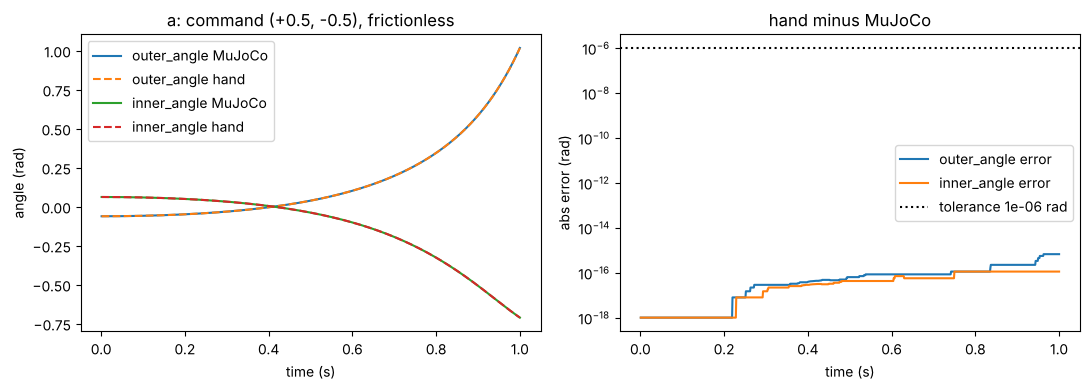

   first acceleration: equation 5.5 gives [ 0.59539785 -0.59486822], first logged rate / dt gives [ 0.59539928 -0.59486968]
b: command (+5, -5) saturates, frictionless: rows = 500, max abs error = 2.22e-16 rad (tolerance 1e-06) PASS
   largest |inner_angle| = 0.81 rad (stays away from the gimbal lock at 1.57 rad)


saved the figure


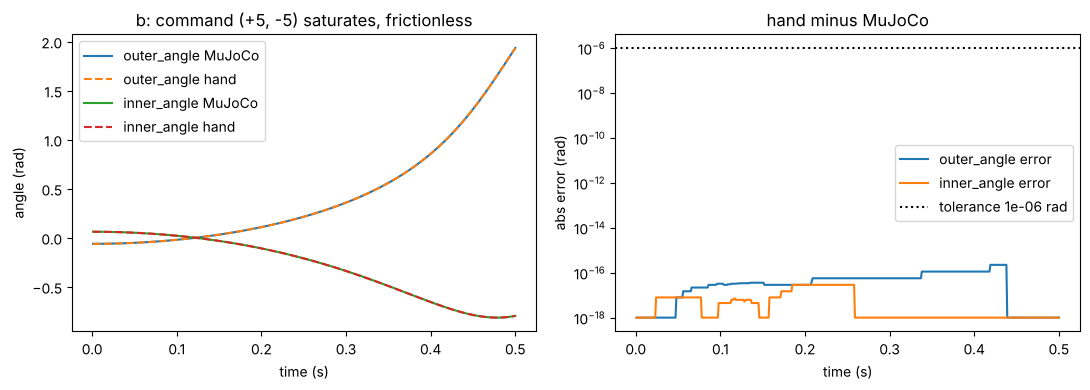

   clip check: command (+5, -5) became torque [ 3. -3.] N*m
c: command (+0.5, -0.5), damping and friction: rows = 1000, max abs error = 6.09e-04 rad (tolerance 1e-03) PASS
   largest |inner_angle| = 0.64 rad (stays away from the gimbal lock at 1.57 rad)


saved the figure


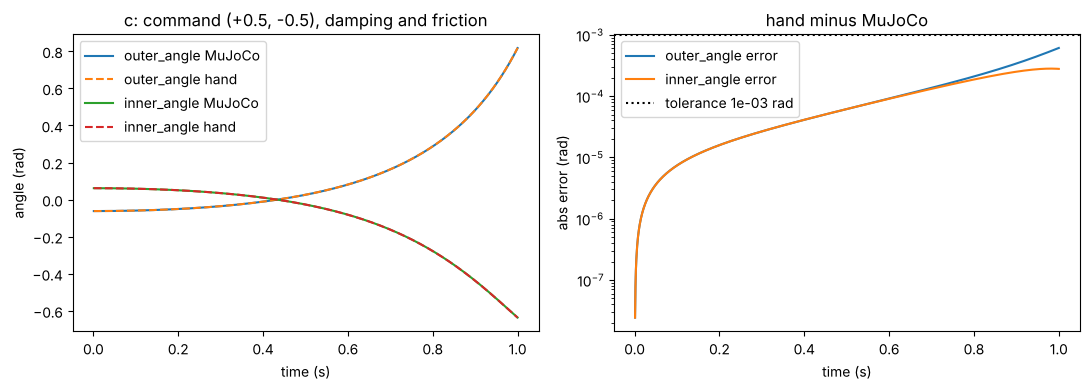

saved the data


In [8]:
# ─────────────────────────────────────────────
# STEP 8: open-loop motor torque, three cases (equations 5.1 to 5.5)
# What we have: constant motor commands, with and without friction
# What we want: hand and MuJoCo trajectories, the clip check and the first-acceleration check
# Why: shows the motor torque enters the equation of motion correctly and saturates at +-3 N*m
# ─────────────────────────────────────────────

def constant_command(command):
    return lambda angles, rates, step_index: np.array(command)


cases = [
    ("a: command (+0.5, -0.5), frictionless", (0.5, -0.5), 1000, 0.0, 0.0, 1e-6, "motor_case_a"),
    ("b: command (+5, -5) saturates, frictionless", (5.0, -5.0), 500, 0.0, 0.0, 1e-6, "motor_case_b"),
    ("c: command (+0.5, -0.5), damping and friction", (0.5, -0.5), 1000, VISCOUS_DAMPING_VALUE, COULOMB_FRICTION_VALUE, 1e-3, "motor_case_c"),
]  # (label, command, steps, damping, friction, tolerance in rad, file stem), tolerances fixed before looking

saved_arrays = {}
for label, command, n_steps, damping, friction, tolerance_rad, file_stem in cases:
    hand_result = simulate(start_angles, start_rates, n_steps, damping, friction, constant_command(command))
    mujoco_result = run_mujoco(start_angles, n_steps, damping, friction, constant_command(command))
    angle_error = compare_angles(hand_result, mujoco_result, tolerance_rad, label)
    print(f"   largest |inner_angle| = {np.abs(hand_result['angles'][:, 1]).max():.2f} rad (stays away from the gimbal lock at 1.57 rad)")
    plot_overlay(hand_result, mujoco_result, angle_error, tolerance_rad, label, file_stem)
    saved_arrays[file_stem + "_angles"] = hand_result["angles"]
    saved_arrays[file_stem + "_motor_torque"] = hand_result["motor_torque"]

    if file_stem == "motor_case_b":
        assert np.allclose(hand_result["motor_torque"][0], [motor_torque_limit, -motor_torque_limit]), "clip check failed"
        print(f"   clip check: command (+5, -5) became torque {hand_result['motor_torque'][0]} N*m")
    if file_stem == "motor_case_a":
        # equation 5.5: first acceleration at rest = (u - g) / M
        expected = (motor_torque_from_command(np.array(command)) - gravity_torque(start_angles)) / mass_matrix_diagonal(start_angles)
        measured = hand_result["rates"][0] / time_step
        print(f"   first acceleration: equation 5.5 gives {expected}, first logged rate / dt gives {measured}")
        assert np.allclose(expected, measured, rtol=1e-2)

np.savez(os.path.join(RESULT_DIR, f"hand_motor_cases_{TIMESTAMP}.npz"), **saved_arrays)
print("saved the data")
